In [ ]:
!pip install -q torchmetrics torch-fidelity

In [ ]:
import os, time, math, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, ConcatDataset, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from torchmetrics.functional.image import structural_similarity_index_measure as hitung_ssim
from torchmetrics.image.fid import FrechetInceptionDistance

In [ ]:
QUICK_TEST = False     # <-- True = tes cepat (1 epoch)

SEED = 42
BATCH = 128
LATENT_DIM = 64
NOISE_DIM = 100
LAMBDA_SPARSE = 5e-3

EPOCHS_MLP = 20
EPOCHS_DEC = 20      # untuk decoder beku (Tahap 4)
EPOCHS_AE = 20
EPOCHS_VAE = 20
EPOCHS_GAN = 30
EPOCHS_DCGAN = 30
EPOCHS_DDPM = 20
T_STEPS = 500
N_FID = 5000

if QUICK_TEST:
    EPOCHS_MLP = EPOCHS_DEC = EPOCHS_AE = EPOCHS_VAE = 1
    EPOCHS_GAN = EPOCHS_DCGAN = EPOCHS_DDPM = 1
    T_STEPS = 50
    N_FID = 500

os.makedirs("figures", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

## **Melakukan penguncian random seed**

In [ ]:
def kunci_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

kunci_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Memakai device:", device)

NAMA_KELAS = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
              "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Memakai device: cuda


## **Menyiapkan dataset Fashion-MNIST**
* Fashion-MNIST berisi 70.000 gambar pakaian 28x28 (60.000 latih + 10.000 uji). Kita gabung dulu, lalu bagi ulang **80% train / 10% validasi / 10% test** sesuai soal.
* `ToTensor()` mengubah nilai piksel menjadi 0-1.
* **DataLoader** = "pengantar data" yang memberi model data per kelompok (batch). Data latih diacak (`shuffle=True`), validasi/test tidak.

In [ ]:
transformasi = transforms.ToTensor()
data_latih_asli = datasets.FashionMNIST("./data", train=True, download=True, transform=transformasi)
data_uji_asli = datasets.FashionMNIST("./data", train=False, download=True, transform=transformasi)

semua_data = ConcatDataset([data_latih_asli, data_uji_asli])
n_total = len(semua_data)
n_train = int(0.8 * n_total)
n_val = int(0.1 * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    semua_data, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED))
print("Jumlah train / val / test =", len(train_set), len(val_set), len(test_set))

train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False, num_workers=2)

# Simpan seluruh data test sebagai satu tensor (dipakai untuk gambar & FID)
X_test = torch.stack([test_set[i][0] for i in range(len(test_set))])
y_test = torch.tensor([test_set[i][1] for i in range(len(test_set))])
print("Bentuk X_test:", X_test.shape)

100%|██████████| 26.4M/26.4M [00:00<00:00, 120MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.06MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 64.8MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.6MB/s]


Jumlah train / val / test = 56000 7000 7000
Bentuk X_test: torch.Size([7000, 1, 28, 28])


# **Fungsi Bantu**

In [ ]:
def tampilkan_baris(daftar_gambar, daftar_judul, nama_file, ukuran=1.1):
    """daftar_gambar: list tensor berbentuk (jumlah,1,28,28) dengan nilai 0-1. Satu tensor = satu baris."""
    n_baris = len(daftar_gambar)
    n_kolom = daftar_gambar[0].shape[0]
    fig, axes = plt.subplots(n_baris, n_kolom, figsize=(n_kolom * ukuran + 2, n_baris * ukuran), squeeze=False)
    for b in range(n_baris):
        for k in range(n_kolom):
            ax = axes[b][k]
            ax.imshow(daftar_gambar[b][k, 0].detach().cpu().numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[b][0].set_ylabel(daftar_judul[b], rotation=0, ha="right", va="center", fontsize=9)
    plt.tight_layout()
    plt.savefig("figures/" + nama_file, dpi=200, bbox_inches="tight")
    plt.show()

def ke_nol_satu(x):
    """Output Tanh ada di rentang -1..1. Fungsi ini mengubahnya ke 0..1 supaya bisa digambar."""
    return ((x + 1) / 2).clamp(0, 1)

In [ ]:
@torch.no_grad()
def hitung_metrik(fungsi_rekonstruksi):
    """fungsi_rekonstruksi: menerima batch gambar, mengembalikan batch gambar hasil rekonstruksi."""
    total_mse = 0.0
    total_psnr = 0.0
    total_ssim = 0.0
    jumlah = 0
    for x, _ in test_loader:
        x = x.to(device)
        x_hasil = fungsi_rekonstruksi(x).clamp(0, 1)
        mse_per_gambar = ((x - x_hasil) ** 2).flatten(1).mean(1)
        psnr_per_gambar = 10 * torch.log10(1.0 / (mse_per_gambar + 1e-10))
        ssim_batch = hitung_ssim(x_hasil, x, data_range=1.0)
        b = x.size(0)
        total_mse += mse_per_gambar.sum().item()
        total_psnr += psnr_per_gambar.sum().item()
        total_ssim += ssim_batch.item() * b
        jumlah += b
    return {"MSE": total_mse / jumlah, "PSNR": total_psnr / jumlah, "SSIM": total_ssim / jumlah}

@torch.no_grad()
def hitung_mse_validasi(loader, fungsi_rekonstruksi):
    """Dipakai untuk memantau overfitting selama training."""
    total, jumlah = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        total += F.mse_loss(fungsi_rekonstruksi(x).clamp(0, 1), x, reduction="sum").item()
        jumlah += x.numel()
    return total / jumlah

In [ ]:
def ukur_latency(fungsi, ulang=20, pemanasan=3):
    """Menjalankan fungsi() beberapa kali lalu mengambil rata-rata waktunya dalam ms."""
    with torch.no_grad():
        for _ in range(pemanasan):
            fungsi()
        if device.type == "cuda":
            torch.cuda.synchronize()
        mulai = time.time()
        for _ in range(ulang):
            fungsi()
        if device.type == "cuda":
            torch.cuda.synchronize()
    return (time.time() - mulai) / ulang * 1000

In [ ]:
fid_metric = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(device)

# Masukkan gambar asli (diulang jadi 3 kanal karena Inception butuh gambar RGB)
for i in range(0, N_FID, 500):
    gambar_asli = X_test[i:min(i + 500, N_FID)].to(device).repeat(1, 3, 1, 1)
    fid_metric.update(gambar_asli, real=True)

@torch.no_grad()
def hitung_fid(fungsi_sampling, n=N_FID, ukuran_batch=500):
    """fungsi_sampling(b) harus mengembalikan b gambar buatan berbentuk (b,1,28,28) bernilai 0-1."""
    fid_metric.reset()
    sudah = 0
    while sudah < n:
        b = min(ukuran_batch, n - sudah)
        gambar_palsu = fungsi_sampling(b).clamp(0, 1).repeat(1, 3, 1, 1)
        fid_metric.update(gambar_palsu, real=False)
        sudah += b
    skor = fid_metric.compute().item()
    fid_metric.reset()
    return skor

hasil = {}
riwayat = {}

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 213MB/s]


# **Tahapan Eksperimen**

# Tahap 1: Latih MLP Classifier Berjenjang*

In [ ]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)   # W1
        self.fc2 = nn.Linear(256, 64)    # W2
        self.fc3 = nn.Linear(64, 10)     # W3

    def fitur_laten(self, x):
        """Menghasilkan z_MLP (64 angka) = keluaran sebelum lapisan klasifikasi akhir."""
        x = x.view(x.size(0), -1)
        h1 = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h1))
        return z

    def forward(self, x):
        return self.fc3(self.fitur_laten(x))

@torch.no_grad()
def hitung_akurasi(model, loader):
    model.eval()
    benar, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        tebakan = model(x).argmax(1)
        benar += (tebakan == y).sum().item()
        total += y.size(0)
    return benar / total

In [ ]:
kunci_seed()
clf = MLPClassifier().to(device)
optimizer = torch.optim.Adam(clf.parameters(), lr=1e-3)

akurasi_val_terbaik = 0
bobot_terbaik = None

for epoch in range(EPOCHS_MLP):
    clf.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(clf(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    akurasi_val = hitung_akurasi(clf, val_loader)
    if akurasi_val > akurasi_val_terbaik:
        akurasi_val_terbaik = akurasi_val
        bobot_terbaik = {k: v.clone() for k, v in clf.state_dict().items()}
    print(f"[MLP] epoch {epoch+1}/{EPOCHS_MLP}  loss={loss.item():.4f}  akurasi_val={akurasi_val:.4f}")

clf.load_state_dict(bobot_terbaik)
clf.eval()
akurasi_test = hitung_akurasi(clf, test_loader)
print(f"\nAKURASI TEST = {akurasi_test*100:.2f}%   (syarat soal: minimal 88%)")
if akurasi_test < 0.88 and not QUICK_TEST:
    print("Akurasi masih < 88%. Naikkan EPOCHS_MLP (mis. 30-40) lalu jalankan ulang sel ini.")

# Ambil matriks bobot terlatih.
W1 = clf.fc1.weight.data    # (256, 784)
W2 = clf.fc2.weight.data    # (64, 256)
W3 = clf.fc3.weight.data    # (10, 64)

# Bekukan semua bobot classifier sesuai Tahap 4
for p in clf.parameters():
    p.requires_grad = False

[MLP] epoch 1/20  loss=0.3414  akurasi_val=0.8339
[MLP] epoch 2/20  loss=0.3680  akurasi_val=0.8494
[MLP] epoch 3/20  loss=0.3468  akurasi_val=0.8656
[MLP] epoch 4/20  loss=0.2790  akurasi_val=0.8703
[MLP] epoch 5/20  loss=0.1484  akurasi_val=0.8747
[MLP] epoch 6/20  loss=0.3571  akurasi_val=0.8729
[MLP] epoch 7/20  loss=0.2495  akurasi_val=0.8817
[MLP] epoch 8/20  loss=0.1826  akurasi_val=0.8759
[MLP] epoch 9/20  loss=0.2425  akurasi_val=0.8791
[MLP] epoch 10/20  loss=0.1711  akurasi_val=0.8847
[MLP] epoch 11/20  loss=0.2397  akurasi_val=0.8874
[MLP] epoch 12/20  loss=0.2825  akurasi_val=0.8909
[MLP] epoch 13/20  loss=0.2319  akurasi_val=0.8907
[MLP] epoch 14/20  loss=0.3115  akurasi_val=0.8924
[MLP] epoch 15/20  loss=0.1820  akurasi_val=0.8926
[MLP] epoch 16/20  loss=0.1927  akurasi_val=0.8934
[MLP] epoch 17/20  loss=0.1380  akurasi_val=0.8929
[MLP] epoch 18/20  loss=0.1792  akurasi_val=0.8940
[MLP] epoch 19/20  loss=0.0719  akurasi_val=0.8947
[MLP] epoch 20/20  loss=0.1502  akurasi_

# Tahap 2 & 3: Proyeksi balik dengan transpos bobot (Wᵀ)

In [ ]:
@torch.no_grad()
def proyeksi_dari_kelas(y_onehot):
    """Tahap 2: dari vektor kelas (B,10) ke gambar."""
    z_hat = F.relu(y_onehot @ W3)             # (B,10) @ (10,64)  -> (B,64)
    h1_hat = F.relu(z_hat @ W2)               # (B,64) @ (64,256) -> (B,256)
    x_hat = torch.sigmoid(h1_hat @ W1)        # (B,256) @ (256,784) -> (B,784)
    return x_hat.view(-1, 1, 28, 28)

@torch.no_grad()
def proyeksi_dari_laten(z_mlp):
    """Tahap 3: dari fitur laten z_MLP (B,64) ke gambar."""
    h1_hat = F.relu(z_mlp @ W2)
    x_hat = torch.sigmoid(h1_hat @ W1)
    return x_hat.view(-1, 1, 28, 28)

# Ambil 1 gambar uji dari tiap kelas (untuk visualisasi)
indeks_kelas = []
for c in range(10):
    indeks_kelas.append((y_test == c).nonzero()[0].item())
X_per_kelas = X_test[indeks_kelas].to(device)

x_dari_kelas = proyeksi_dari_kelas(torch.eye(10, device=device))      # Tahap 2
x_dari_laten = proyeksi_dari_laten(clf.fitur_laten(X_per_kelas))      # Tahap 3

def rekon_transpos(x):
    return proyeksi_dari_laten(clf.fitur_laten(x))

hasil["MLP Wt (Tahap 3)"] = hitung_metrik(rekon_transpos)
print("Metrik proyeksi transpos (Tahap 3):", hasil["MLP Wt (Tahap 3)"])

Metrik proyeksi transpos (Tahap 3): {'MSE': 0.29134854670933313, 'PSNR': 5.401752223423549, 'SSIM': 0.055456964773791174}


# Tahap 4: Evaluasi Kandungan Informasi Latent Features (Frozen Latent Decoding):

In [ ]:
class DecoderMLP(nn.Module):
    def __init__(self, laten=64):
        super().__init__()
        self.lapisan = nn.Sequential(
            nn.Linear(laten, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid())

    def forward(self, z):
        return self.lapisan(z).view(-1, 1, 28, 28)

kunci_seed()
decoder_beku = DecoderMLP(LATENT_DIM).to(device)
optimizer = torch.optim.Adam(decoder_beku.parameters(), lr=1e-3)   # hanya decoder yang dilatih

for epoch in range(EPOCHS_DEC):
    decoder_beku.train()
    total_loss, jumlah = 0.0, 0
    for x, _ in train_loader:
        x = x.to(device)
        with torch.no_grad():
            z = clf.fitur_laten(x)                 # fitur laten BEKU
        loss = F.mse_loss(decoder_beku(z), x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        jumlah += x.size(0)
    print(f"[Decoder beku] epoch {epoch+1}/{EPOCHS_DEC}  loss={total_loss/jumlah:.5f}")
decoder_beku.eval()

def rekon_decoder_beku(x):
    return decoder_beku(clf.fitur_laten(x))

hasil["MLP Frozen Decoder"] = hitung_metrik(rekon_decoder_beku)
print("Metrik decoder beku (z_MLP):", hasil["MLP Frozen Decoder"])

[Decoder beku] epoch 1/20  loss=0.03595
[Decoder beku] epoch 2/20  loss=0.02444
[Decoder beku] epoch 3/20  loss=0.02219
[Decoder beku] epoch 4/20  loss=0.02101
[Decoder beku] epoch 5/20  loss=0.02026
[Decoder beku] epoch 6/20  loss=0.01970
[Decoder beku] epoch 7/20  loss=0.01927
[Decoder beku] epoch 8/20  loss=0.01895
[Decoder beku] epoch 9/20  loss=0.01869
[Decoder beku] epoch 10/20  loss=0.01844
[Decoder beku] epoch 11/20  loss=0.01827
[Decoder beku] epoch 12/20  loss=0.01807
[Decoder beku] epoch 13/20  loss=0.01793
[Decoder beku] epoch 14/20  loss=0.01776
[Decoder beku] epoch 15/20  loss=0.01766
[Decoder beku] epoch 16/20  loss=0.01755
[Decoder beku] epoch 17/20  loss=0.01746
[Decoder beku] epoch 18/20  loss=0.01735
[Decoder beku] epoch 19/20  loss=0.01726
[Decoder beku] epoch 20/20  loss=0.01721
Metrik decoder beku (z_MLP): {'MSE': 0.01776196895326887, 'PSNR': 18.266612025669644, 'SSIM': 0.7082055856840951}


# Tahap 5: Uji Sampling Generatif pada Ruang Laten MLP Classifier:

In [ ]:
with torch.no_grad():
    semua_z = torch.cat([clf.fitur_laten(x.to(device)) for x, _ in test_loader])   # (7000, 64)
    mu_z = semua_z.mean(0)
    sigma_z = semua_z.std(0)

    kunci_seed()
    z_acak = mu_z + sigma_z * torch.randn(10, LATENT_DIM, device=device)
    x_sampel_mlp = decoder_beku(z_acak)
print("Selesai. Hasilnya akan ditampilkan di Figur 3.")

Selesai. Hasilnya akan ditampilkan di Figur 3.


# **Melatih model-model generatif**

# Vanilla Autoencoder & Sparse Autoencoder
* **Vanilla AE:** hanya MSE.
* **Sparse AE:** arsitektur sama, tapi ditambah hukuman `λ × rata-rata |h|` pada lapisan tersembunyi (256 unit) supaya sebagian besar unit **bernilai ~0** (jarang aktif).

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, laten=64):
        super().__init__()
        self.enc1 = nn.Linear(784, 256)
        self.enc2 = nn.Linear(256, laten)
        self.dec1 = nn.Linear(laten, 256)
        self.dec2 = nn.Linear(256, 784)

    def encode(self, x):
        x = x.view(x.size(0), -1)
        h = F.relu(self.enc1(x))      # h = lapisan tersembunyi (yang dikenai hukuman sparsity)
        z = self.enc2(h)              # z = ringkasan 64 angka
        return z, h

    def decode(self, z):
        h = F.relu(self.dec1(z))
        x_hasil = torch.sigmoid(self.dec2(h))
        return x_hasil.view(-1, 1, 28, 28)

    def forward(self, x):
        z, h = self.encode(x)
        return self.decode(z), z, h

def latih_autoencoder(lam, jumlah_epoch, nama):
    """lam = 0 untuk Vanilla AE, lam > 0 untuk Sparse AE."""
    kunci_seed()
    model = Autoencoder(LATENT_DIM).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    catatan = {"train_loss": [], "val_mse": []}
    daftar_waktu = []

    for epoch in range(jumlah_epoch):
        model.train()
        mulai = time.time()
        total_loss, jumlah = 0.0, 0
        for x, _ in train_loader:
            x = x.to(device)
            x_hasil, z, h = model(x)
            loss_rekonstruksi = F.mse_loss(x_hasil, x)
            loss_sparsity = h.abs().mean()                 # ukuran "seberapa aktif" lapisan h
            loss = loss_rekonstruksi + lam * loss_sparsity
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * x.size(0)
            jumlah += x.size(0)
        daftar_waktu.append(time.time() - mulai)

        model.eval()
        def rekon_untuk_val(x):
            return model(x)[0]
        mse_val = hitung_mse_validasi(val_loader, rekon_untuk_val)
        catatan["train_loss"].append(total_loss / jumlah)
        catatan["val_mse"].append(mse_val)
        print(f"[{nama}] epoch {epoch+1}/{jumlah_epoch}  loss={total_loss/jumlah:.5f}  val_mse={mse_val:.5f}")

    model.eval()
    return model, catatan, float(np.mean(daftar_waktu))

In [ ]:
vanilla_ae, catatan_vanilla, waktu_vanilla = latih_autoencoder(0.0, EPOCHS_AE, "Vanilla AE")
sparse_ae, catatan_sparse, waktu_sparse = latih_autoencoder(LAMBDA_SPARSE, EPOCHS_AE, "Sparse AE")
riwayat["Vanilla AE"] = catatan_vanilla
riwayat["Sparse AE"] = catatan_sparse

[Vanilla AE] epoch 1/20  loss=0.03183  val_mse=0.01862
[Vanilla AE] epoch 2/20  loss=0.01654  val_mse=0.01560
[Vanilla AE] epoch 3/20  loss=0.01394  val_mse=0.01326
[Vanilla AE] epoch 4/20  loss=0.01239  val_mse=0.01195
[Vanilla AE] epoch 5/20  loss=0.01129  val_mse=0.01109
[Vanilla AE] epoch 6/20  loss=0.01050  val_mse=0.01035
[Vanilla AE] epoch 7/20  loss=0.00986  val_mse=0.00989
[Vanilla AE] epoch 8/20  loss=0.00939  val_mse=0.00944
[Vanilla AE] epoch 9/20  loss=0.00897  val_mse=0.00902
[Vanilla AE] epoch 10/20  loss=0.00862  val_mse=0.00874
[Vanilla AE] epoch 11/20  loss=0.00833  val_mse=0.00850
[Vanilla AE] epoch 12/20  loss=0.00805  val_mse=0.00821
[Vanilla AE] epoch 13/20  loss=0.00782  val_mse=0.00796
[Vanilla AE] epoch 14/20  loss=0.00763  val_mse=0.00780
[Vanilla AE] epoch 15/20  loss=0.00744  val_mse=0.00768
[Vanilla AE] epoch 16/20  loss=0.00728  val_mse=0.00752
[Vanilla AE] epoch 17/20  loss=0.00714  val_mse=0.00736
[Vanilla AE] epoch 18/20  loss=0.00701  val_mse=0.00727
[

In [ ]:
@torch.no_grad()
def persen_unit_nol(model, batas=1e-2):
    semua_h = torch.cat([model.encode(x.to(device))[1] for x, _ in test_loader])
    return (semua_h < batas).float().mean().item() * 100

print(f"Unit hidden bernilai ~0 -> Vanilla AE: {persen_unit_nol(vanilla_ae):.1f}%  |  Sparse AE: {persen_unit_nol(sparse_ae):.1f}%")

def rekon_vanilla(x):
    return vanilla_ae(x)[0]

def rekon_sparse(x):
    return sparse_ae(x)[0]

x64 = X_test[:64].to(device)
def jalan_vanilla():
    vanilla_ae(x64)
def jalan_sparse():
    sparse_ae(x64)

hasil["Vanilla AE"] = hitung_metrik(rekon_vanilla)
hasil["Vanilla AE"]["waktu"] = waktu_vanilla
hasil["Vanilla AE"]["latency"] = ukur_latency(jalan_vanilla)

hasil["Sparse AE"] = hitung_metrik(rekon_sparse)
hasil["Sparse AE"]["waktu"] = waktu_sparse
hasil["Sparse AE"]["latency"] = ukur_latency(jalan_sparse)

print("Vanilla AE:", hasil["Vanilla AE"])
print("Sparse AE :", hasil["Sparse AE"])

Unit hidden bernilai ~0 -> Vanilla AE: 43.9%  |  Sparse AE: 76.6%
Vanilla AE: {'MSE': 0.007077677982194083, 'PSNR': 22.564556815011162, 'SSIM': 0.8550803630011422, 'waktu': 7.188500237464905, 'latency': 0.44285058975219727}
Sparse AE : {'MSE': 0.008239105803625925, 'PSNR': 21.866803728376116, 'SSIM': 0.8367834392275129, 'waktu': 7.106728041172028, 'latency': 0.24366378784179688}


# Variational Autoencoder

In [ ]:
class VAE(nn.Module):
    def __init__(self, laten=64):
        super().__init__()
        self.enc1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, laten)
        self.fc_logvar = nn.Linear(256, laten)
        self.dec1 = nn.Linear(laten, 256)
        self.dec2 = nn.Linear(256, 784)

    def encode(self, x):
        h = F.relu(self.enc1(x.view(x.size(0), -1)))
        return self.fc_mu(h), self.fc_logvar(h)

    def ambil_sampel_z(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        h = F.relu(self.dec1(z))
        return torch.sigmoid(self.dec2(h)).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.ambil_sampel_z(mu, logvar)
        return self.decode(z), mu, logvar

kunci_seed()
vae = VAE(LATENT_DIM).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
catatan_vae = {"train_loss": [], "rekonstruksi": [], "kl": []}
daftar_waktu = []

for epoch in range(EPOCHS_VAE):
    vae.train()
    mulai = time.time()
    tot_loss, tot_rek, tot_kl, jumlah = 0.0, 0.0, 0.0, 0
    for x, _ in train_loader:
        x = x.to(device)
        B = x.size(0)
        x_hasil, mu, logvar = vae(x)
        loss_rek = F.binary_cross_entropy(x_hasil.view(B, -1), x.view(B, -1), reduction="sum") / B
        loss_kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / B
        loss = loss_rek + loss_kl
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        tot_loss += loss.item() * B
        tot_rek += loss_rek.item() * B
        tot_kl += loss_kl.item() * B
        jumlah += B
    daftar_waktu.append(time.time() - mulai)
    catatan_vae["train_loss"].append(tot_loss / jumlah)
    catatan_vae["rekonstruksi"].append(tot_rek / jumlah)
    catatan_vae["kl"].append(tot_kl / jumlah)
    print(f"[VAE] epoch {epoch+1}/{EPOCHS_VAE}  loss={tot_loss/jumlah:.2f}  rekonstruksi={tot_rek/jumlah:.2f}  kl={tot_kl/jumlah:.2f}")

vae.eval()
riwayat["VAE"] = catatan_vae

[VAE] epoch 1/20  loss=299.93  rekonstruksi=285.26  kl=14.67
[VAE] epoch 2/20  loss=266.94  rekonstruksi=250.74  kl=16.21
[VAE] epoch 3/20  loss=257.95  rekonstruksi=242.52  kl=15.42
[VAE] epoch 4/20  loss=252.86  rekonstruksi=237.85  kl=15.02
[VAE] epoch 5/20  loss=249.72  rekonstruksi=234.73  kl=14.99
[VAE] epoch 6/20  loss=247.78  rekonstruksi=232.73  kl=15.05
[VAE] epoch 7/20  loss=246.55  rekonstruksi=231.38  kl=15.18
[VAE] epoch 8/20  loss=245.67  rekonstruksi=230.41  kl=15.26
[VAE] epoch 9/20  loss=244.96  rekonstruksi=229.60  kl=15.36
[VAE] epoch 10/20  loss=244.44  rekonstruksi=229.01  kl=15.44
[VAE] epoch 11/20  loss=243.97  rekonstruksi=228.44  kl=15.53
[VAE] epoch 12/20  loss=243.58  rekonstruksi=227.98  kl=15.60
[VAE] epoch 13/20  loss=243.25  rekonstruksi=227.62  kl=15.63
[VAE] epoch 14/20  loss=242.96  rekonstruksi=227.26  kl=15.70
[VAE] epoch 15/20  loss=242.75  rekonstruksi=227.04  kl=15.71
[VAE] epoch 16/20  loss=242.49  rekonstruksi=226.75  kl=15.74
[VAE] epoch 17/20

In [ ]:
def rekon_vae(x):
    mu, logvar = vae.encode(x)
    return vae.decode(mu)

def sampel_vae(n):
    z = torch.randn(n, LATENT_DIM, device=device)
    return vae.decode(z)

def jalan_vae():
    sampel_vae(64)

hasil["VAE"] = hitung_metrik(rekon_vae)
hasil["VAE"]["waktu"] = float(np.mean(daftar_waktu))
hasil["VAE"]["latency"] = ukur_latency(jalan_vae)
hasil["VAE"]["FID"] = hitung_fid(sampel_vae)
print("VAE:", hasil["VAE"])

VAE: {'MSE': 0.013687553576060704, 'PSNR': 19.453301112583706, 'SSIM': 0.7595790455000742, 'waktu': 7.4198129892349245, 'latency': 0.11903047561645508, 'FID': 91.9588394165039}


# Vanilla GAN (berbasis NLP)

In [ ]:
class GeneratorMLP(nn.Module):
    def __init__(self, nz=100):
        super().__init__()
        self.lapisan = nn.Sequential(
            nn.Linear(nz, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, 784), nn.Tanh())

    def forward(self, z):
        return self.lapisan(z).view(-1, 1, 28, 28)

class DiscriminatorMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.lapisan = nn.Sequential(
            nn.Linear(784, 1024), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(1024, 512), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1))          # keluaran 1 angka (logit): besar = asli, kecil = palsu

    def forward(self, x):
        return self.lapisan(x.view(x.size(0), -1))

def latih_gan(G, D, jumlah_epoch, nama):
    """Dipakai untuk Vanilla GAN dan DCGAN (loop latihnya sama)."""
    kunci_seed()
    G, D = G.to(device), D.to(device)
    opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    kriteria = nn.BCEWithLogitsLoss()
    catatan = {"loss_d": [], "loss_g": []}
    daftar_waktu = []

    for epoch in range(jumlah_epoch):
        G.train()
        D.train()
        mulai = time.time()
        tot_d, tot_g, jumlah = 0.0, 0.0, 0
        for x, _ in train_loader:
            x = x.to(device) * 2 - 1
            B = x.size(0)
            label_asli = torch.ones(B, 1, device=device)
            label_palsu = torch.zeros(B, 1, device=device)

            # (1) Latih Discriminator: gambar asli -> 1, gambar palsu -> 0
            z = torch.randn(B, NOISE_DIM, device=device)
            gambar_palsu = G(z).detach()
            loss_d = kriteria(D(x).view(B, 1), label_asli) + kriteria(D(gambar_palsu).view(B, 1), label_palsu)
            opt_D.zero_grad()
            loss_d.backward()
            opt_D.step()

            # (2) Latih Generator: berusaha membuat D mengira gambar palsunya "asli" (label 1)
            z = torch.randn(B, NOISE_DIM, device=device)
            loss_g = kriteria(D(G(z)).view(B, 1), label_asli)
            opt_G.zero_grad()
            loss_g.backward()
            opt_G.step()

            tot_d += loss_d.item() * B
            tot_g += loss_g.item() * B
            jumlah += B
        daftar_waktu.append(time.time() - mulai)
        catatan["loss_d"].append(tot_d / jumlah)
        catatan["loss_g"].append(tot_g / jumlah)
        print(f"[{nama}] epoch {epoch+1}/{jumlah_epoch}  loss_D={tot_d/jumlah:.3f}  loss_G={tot_g/jumlah:.3f}")

    G.eval()
    return G, catatan, float(np.mean(daftar_waktu))

In [ ]:
kunci_seed()
G_gan, catatan_gan, waktu_gan = latih_gan(GeneratorMLP(NOISE_DIM), DiscriminatorMLP(), EPOCHS_GAN, "Vanilla GAN")
riwayat["Vanilla GAN"] = catatan_gan

def sampel_gan(n):
    z = torch.randn(n, NOISE_DIM, device=device)
    return ke_nol_satu(G_gan(z))

def jalan_gan():
    sampel_gan(64)

hasil["Vanilla GAN"] = {"waktu": waktu_gan, "latency": ukur_latency(jalan_gan)}
hasil["Vanilla GAN"]["FID"] = hitung_fid(sampel_gan)
print("Vanilla GAN:", hasil["Vanilla GAN"])

[Vanilla GAN] epoch 1/30  loss_D=0.542  loss_G=2.983
[Vanilla GAN] epoch 2/30  loss_D=0.664  loss_G=3.001
[Vanilla GAN] epoch 3/30  loss_D=0.712  loss_G=2.491
[Vanilla GAN] epoch 4/30  loss_D=0.788  loss_G=1.984
[Vanilla GAN] epoch 5/30  loss_D=0.883  loss_G=1.731
[Vanilla GAN] epoch 6/30  loss_D=0.912  loss_G=1.698
[Vanilla GAN] epoch 7/30  loss_D=0.974  loss_G=1.554
[Vanilla GAN] epoch 8/30  loss_D=1.009  loss_G=1.464
[Vanilla GAN] epoch 9/30  loss_D=1.038  loss_G=1.385
[Vanilla GAN] epoch 10/30  loss_D=1.081  loss_G=1.309
[Vanilla GAN] epoch 11/30  loss_D=1.124  loss_G=1.220
[Vanilla GAN] epoch 12/30  loss_D=1.140  loss_G=1.170
[Vanilla GAN] epoch 13/30  loss_D=1.158  loss_G=1.151
[Vanilla GAN] epoch 14/30  loss_D=1.178  loss_G=1.108
[Vanilla GAN] epoch 15/30  loss_D=1.192  loss_G=1.083
[Vanilla GAN] epoch 16/30  loss_D=1.194  loss_G=1.076
[Vanilla GAN] epoch 17/30  loss_D=1.206  loss_G=1.051
[Vanilla GAN] epoch 18/30  loss_D=1.215  loss_G=1.027
[Vanilla GAN] epoch 19/30  loss_D=1.2

# DCGAN (GAN konvolusional)

In [ ]:
class GeneratorDC(nn.Module):
    def __init__(self, nz=100):
        super().__init__()
        self.lapisan = nn.Sequential(
            nn.ConvTranspose2d(nz, 256, 7, 1, 0, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),    # -> 7x7
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),   # -> 14x14
            nn.ConvTranspose2d(128, 1, 4, 2, 1, bias=False), nn.Tanh())                              # -> 28x28

    def forward(self, z):
        return self.lapisan(z.view(z.size(0), -1, 1, 1))

class DiscriminatorDC(nn.Module):
    def __init__(self):
        super().__init__()
        self.lapisan = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),                           # -> 14x14
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),    # -> 7x7
            nn.Conv2d(128, 1, 7, 1, 0, bias=False))                                                   # -> 1x1

    def forward(self, x):
        return self.lapisan(x).view(-1, 1)

def inisialisasi_dcgan(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

kunci_seed()
G_awal = GeneratorDC(NOISE_DIM)
D_awal = DiscriminatorDC()
G_awal.apply(inisialisasi_dcgan)
D_awal.apply(inisialisasi_dcgan)

G_dc, catatan_dc, waktu_dc = latih_gan(G_awal, D_awal, EPOCHS_DCGAN, "DCGAN")
riwayat["DCGAN"] = catatan_dc

def sampel_dcgan(n):
    z = torch.randn(n, NOISE_DIM, device=device)
    return ke_nol_satu(G_dc(z))

def jalan_dcgan():
    sampel_dcgan(64)

hasil["DCGAN"] = {"waktu": waktu_dc, "latency": ukur_latency(jalan_dcgan)}
hasil["DCGAN"]["FID"] = hitung_fid(sampel_dcgan)
print("DCGAN:", hasil["DCGAN"])

[DCGAN] epoch 1/30  loss_D=0.695  loss_G=1.617
[DCGAN] epoch 2/30  loss_D=0.641  loss_G=1.704
[DCGAN] epoch 3/30  loss_D=0.856  loss_G=1.369
[DCGAN] epoch 4/30  loss_D=0.938  loss_G=1.266
[DCGAN] epoch 5/30  loss_D=0.965  loss_G=1.245
[DCGAN] epoch 6/30  loss_D=0.992  loss_G=1.215
[DCGAN] epoch 7/30  loss_D=1.018  loss_G=1.177
[DCGAN] epoch 8/30  loss_D=1.058  loss_G=1.161
[DCGAN] epoch 9/30  loss_D=1.065  loss_G=1.144
[DCGAN] epoch 10/30  loss_D=1.103  loss_G=1.129
[DCGAN] epoch 11/30  loss_D=1.094  loss_G=1.105
[DCGAN] epoch 12/30  loss_D=1.119  loss_G=1.093
[DCGAN] epoch 13/30  loss_D=1.124  loss_G=1.085
[DCGAN] epoch 14/30  loss_D=1.132  loss_G=1.068
[DCGAN] epoch 15/30  loss_D=1.130  loss_G=1.065
[DCGAN] epoch 16/30  loss_D=1.145  loss_G=1.058
[DCGAN] epoch 17/30  loss_D=1.144  loss_G=1.055
[DCGAN] epoch 18/30  loss_D=1.156  loss_G=1.056
[DCGAN] epoch 19/30  loss_D=1.158  loss_G=1.055
[DCGAN] epoch 20/30  loss_D=1.154  loss_G=1.046
[DCGAN] epoch 21/30  loss_D=1.165  loss_G=1.053
[

# DDPM (Diffusion)

In [ ]:
def embedding_waktu(t, dim):
    """Mengubah nomor langkah t menjadi vektor (mirip positional encoding di Transformer)."""
    setengah = dim // 2
    frekuensi = torch.exp(-math.log(10000) * torch.arange(setengah, device=t.device) / setengah)
    sudut = t[:, None].float() * frekuensi[None]
    return torch.cat([sudut.sin(), sudut.cos()], dim=1)

class BlokUNet(nn.Module):
    def __init__(self, masuk, keluar, dim_waktu):
        super().__init__()
        self.conv1 = nn.Conv2d(masuk, keluar, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, keluar)
        self.conv2 = nn.Conv2d(keluar, keluar, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, keluar)
        self.proyeksi_waktu = nn.Linear(dim_waktu, keluar)
        self.aktivasi = nn.SiLU()

    def forward(self, x, emb_waktu):
        h = self.aktivasi(self.norm1(self.conv1(x)))
        h = h + self.proyeksi_waktu(emb_waktu)[:, :, None, None]     # suntikkan info langkah t
        h = self.aktivasi(self.norm2(self.conv2(h)))
        return h

class UNetKecil(nn.Module):
    def __init__(self, dasar=64, dim_waktu=128):
        super().__init__()
        self.dim_waktu = dim_waktu
        self.mlp_waktu = nn.Sequential(nn.Linear(dim_waktu, dim_waktu), nn.SiLU(), nn.Linear(dim_waktu, dim_waktu))
        self.turun1 = BlokUNet(1, dasar, dim_waktu)
        self.turun2 = BlokUNet(dasar, dasar * 2, dim_waktu)
        self.tengah = BlokUNet(dasar * 2, dasar * 4, dim_waktu)
        self.naik1 = BlokUNet(dasar * 4 + dasar * 2, dasar * 2, dim_waktu)
        self.naik2 = BlokUNet(dasar * 2 + dasar, dasar, dim_waktu)
        self.keluaran = nn.Conv2d(dasar, 1, 1)

    def forward(self, x, t):
        e = self.mlp_waktu(embedding_waktu(t, self.dim_waktu))
        d1 = self.turun1(x, e)                                   # (B, 64, 28, 28)
        d2 = self.turun2(F.max_pool2d(d1, 2), e)                 # (B,128, 14, 14)
        m = self.tengah(F.max_pool2d(d2, 2), e)                  # (B,256,  7,  7)
        n1 = self.naik1(torch.cat([F.interpolate(m, scale_factor=2), d2], dim=1), e)    # (B,128,14,14)
        n2 = self.naik2(torch.cat([F.interpolate(n1, scale_factor=2), d1], dim=1), e)   # (B, 64,28,28)
        return self.keluaran(n2)

In [ ]:
betas = torch.linspace(1e-4 * 1000 / T_STEPS, 0.02 * 1000 / T_STEPS, T_STEPS, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)

kunci_seed()
ddpm = UNetKecil().to(device)
optimizer = torch.optim.Adam(ddpm.parameters(), lr=2e-4)
catatan_ddpm = {"train_loss": []}
daftar_waktu = []

for epoch in range(EPOCHS_DDPM):
    ddpm.train()
    mulai = time.time()
    total_loss, jumlah = 0.0, 0
    for x, _ in train_loader:
        x0 = x.to(device) * 2 - 1
        B = x0.size(0)
        t = torch.randint(0, T_STEPS, (B,), device=device)         # pilih langkah acak
        noise = torch.randn_like(x0)                               # noise asli
        ab = alpha_bar[t].view(B, 1, 1, 1)
        x_t = ab.sqrt() * x0 + (1 - ab).sqrt() * noise             # gambar + noise (proses forward)
        loss = F.mse_loss(ddpm(x_t, t), noise)                     # U-Net menebak noise
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * B
        jumlah += B
    daftar_waktu.append(time.time() - mulai)
    catatan_ddpm["train_loss"].append(total_loss / jumlah)
    print(f"[DDPM] epoch {epoch+1}/{EPOCHS_DDPM}  loss={total_loss/jumlah:.5f}")

ddpm.eval()
riwayat["DDPM"] = catatan_ddpm

[DDPM] epoch 1/20  loss=0.10062
[DDPM] epoch 2/20  loss=0.05577
[DDPM] epoch 3/20  loss=0.05077
[DDPM] epoch 4/20  loss=0.04788
[DDPM] epoch 5/20  loss=0.04604
[DDPM] epoch 6/20  loss=0.04507
[DDPM] epoch 7/20  loss=0.04342
[DDPM] epoch 8/20  loss=0.04333
[DDPM] epoch 9/20  loss=0.04259
[DDPM] epoch 10/20  loss=0.04237
[DDPM] epoch 11/20  loss=0.04098
[DDPM] epoch 12/20  loss=0.04065
[DDPM] epoch 13/20  loss=0.04110
[DDPM] epoch 14/20  loss=0.04067
[DDPM] epoch 15/20  loss=0.03996
[DDPM] epoch 16/20  loss=0.03962
[DDPM] epoch 17/20  loss=0.03980
[DDPM] epoch 18/20  loss=0.03948
[DDPM] epoch 19/20  loss=0.03945
[DDPM] epoch 20/20  loss=0.03967


In [ ]:
@torch.no_grad()
def sampel_ddpm(n, simpan_langkah=0):
    x = torch.randn(n, 1, 28, 28, device=device)
    titik_simpan = set()
    if simpan_langkah > 0:
        titik_simpan = set(np.linspace(T_STEPS - 1, 0, simpan_langkah).astype(int).tolist())
    lintasan = []
    if simpan_langkah > 0:
        lintasan.append(x.clone())

    for t in reversed(range(T_STEPS)):
        t_batch = torch.full((n,), t, device=device, dtype=torch.long)
        noise_tebakan = ddpm(x, t_batch)
        rata2 = (x - betas[t] / (1 - alpha_bar[t]).sqrt() * noise_tebakan) / alphas[t].sqrt()
        if t > 0:
            x = rata2 + betas[t].sqrt() * torch.randn_like(x)
        else:
            x = rata2
        if t in titik_simpan:
            lintasan.append(x.clone())

    if simpan_langkah > 0:
        return ke_nol_satu(x), lintasan
    return ke_nol_satu(x)

def jalan_ddpm():
    sampel_ddpm(64)

hasil["DDPM"] = {"waktu": float(np.mean(daftar_waktu))}
hasil["DDPM"]["latency"] = ukur_latency(jalan_ddpm, ulang=2, pemanasan=1)
hasil["DDPM"]["FID"] = hitung_fid(sampel_ddpm)
print("DDPM:", hasil["DDPM"])

DDPM: {'waktu': 32.46719777584076, 'latency': 7022.266268730164, 'FID': 26.83380126953125}


# **Tabel dan Lima Figur**

# Tabel Komparasi

In [ ]:
susunan = [
    ("Vanilla Autoencoder", "64", "Vanilla AE"),
    ("Sparse Autoencoder", "64 (bottleneck) / 256 (sparse)", "Sparse AE"),
    ("VAE", "64", "VAE"),
    ("GAN", "100 (prior noise)", "Vanilla GAN"),
    ("DCGAN", "100 (prior noise)", "DCGAN"),
    ("DDPM", "28x28 (dimensi citra)", "DDPM"),
]
baris_tabel = []
for nama, dim, kunci in susunan:
    r = hasil[kunci]
    baris_tabel.append({
        "Arsitektur": nama,
        "Dim Laten": dim,
        "Waktu/Epoch (s)": round(r["waktu"], 2),
        "Latency (ms/batch 64)": round(r["latency"], 2),
        "Test MSE": round(r["MSE"], 5) if "MSE" in r else "N/A",
        "Test PSNR (dB)": round(r["PSNR"], 2) if "PSNR" in r else "N/A",
        "Test SSIM": round(r["SSIM"], 4) if "SSIM" in r else "N/A",
        "FID": round(r["FID"], 2) if "FID" in r else "N/A",
        "Kestabilan Training": "(isi manual dari kurva loss)",
    })
tabel = pd.DataFrame(baris_tabel)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
print(tabel.to_string(index=False))
tabel.to_csv("tabel_komparasi.csv", index=False)

# Tabel khusus bukti MLP
tabel_mlp = pd.DataFrame([
    {"Metode": "MLP transpos Wt dari z_MLP (Tahap 3)", **{k: round(v, 5) for k, v in hasil["MLP Wt (Tahap 3)"].items()}},
    {"Metode": "MLP Frozen Decoder (z_MLP)", **{k: round(v, 5) for k, v in hasil["MLP Frozen Decoder"].items()}},
    {"Metode": "Vanilla AE (z_AE)", **{k: round(hasil["Vanilla AE"][k], 5) for k in ["MSE", "PSNR", "SSIM"]}},
])
print("\n", tabel_mlp.to_string(index=False))
tabel_mlp.to_csv("tabel_mlp_vs_ae.csv", index=False)
print(f"\nAkurasi test MLP = {akurasi_test*100:.2f}%")

         Arsitektur                      Dim Laten  Waktu/Epoch (s)  Latency (ms/batch 64) Test MSE Test PSNR (dB) Test SSIM     FID          Kestabilan Training
Vanilla Autoencoder                             64             7.19                   0.44  0.00708          22.56    0.8551     N/A (isi manual dari kurva loss)
 Sparse Autoencoder 64 (bottleneck) / 256 (sparse)             7.11                   0.24  0.00824          21.87    0.8368     N/A (isi manual dari kurva loss)
                VAE                             64             7.42                   0.12  0.01369          19.45    0.7596   91.96 (isi manual dari kurva loss)
                GAN              100 (prior noise)             9.41                   0.30      N/A            N/A       N/A  129.96 (isi manual dari kurva loss)
              DCGAN              100 (prior noise)            26.56                   8.51      N/A            N/A       N/A   22.74 (isi manual dari kurva loss)
               DDPM         

# Figur 1: Grid rekonstruksi
Baris 1 = gambar asli, baris 2 = Vanilla AE, baris 3 = Sparse AE, baris 4 = VAE. **Perhatikan:** mana yang paling tajam, mana yang paling buram.

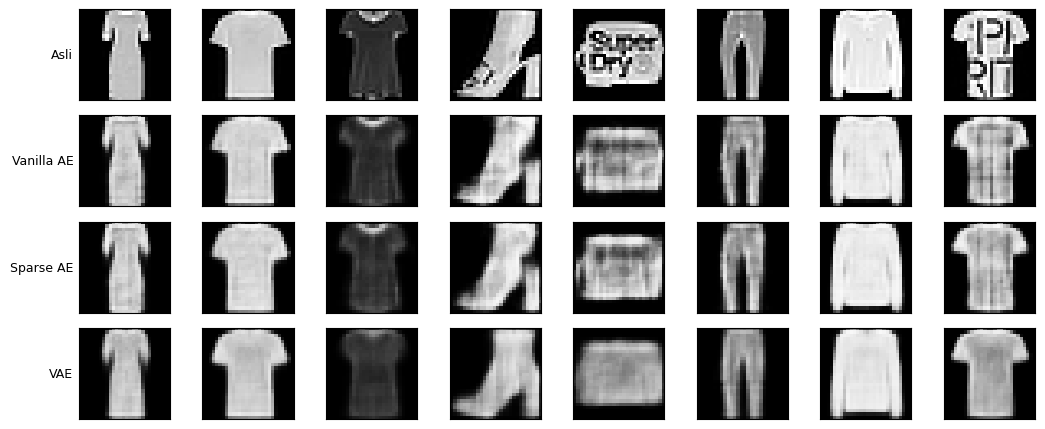

In [ ]:
with torch.no_grad():
    x8 = X_test[:8].to(device)
    tampilkan_baris(
        [x8, vanilla_ae(x8)[0], sparse_ae(x8)[0], rekon_vae(x8)],
        ["Asli", "Vanilla AE", "Sparse AE", "VAE"],
        "fig1_rekonstruksi.png")

# Figur 2: Sampling acak 4x4 dari tiap model generatif
Panel A = VAE, B = Vanilla GAN, C = DCGAN, D = DDPM. **Perhatikan:** ketajaman, kualitas tekstur, dan keragaman jenis pakaian (mode diversity).

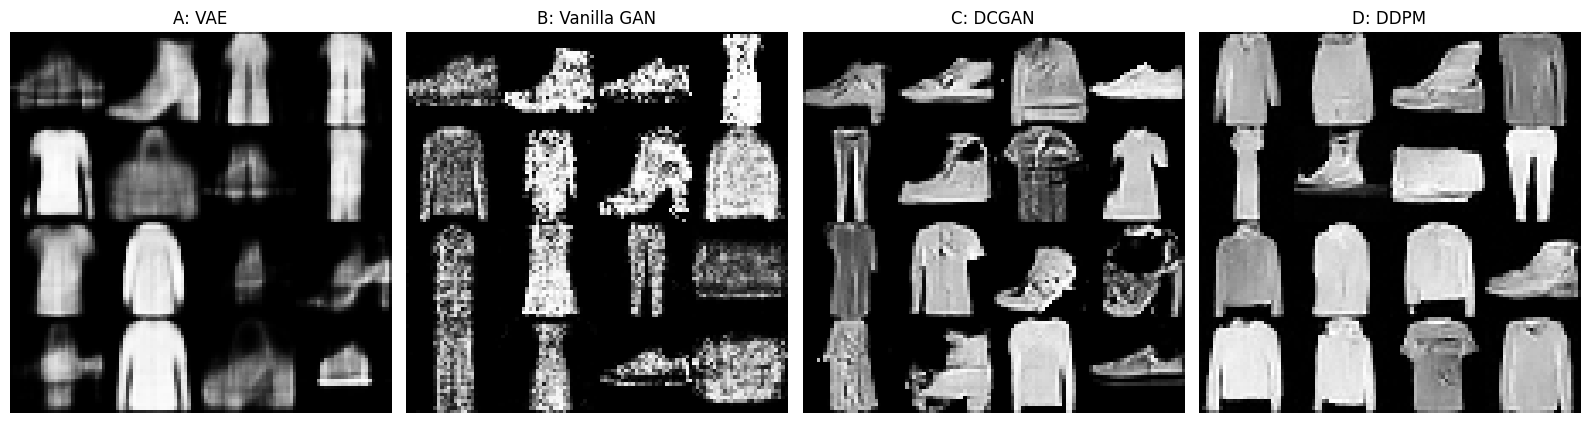

In [ ]:
def gambar_grid_4x4(daftar_panel, nama_file):
    fig, axes = plt.subplots(1, len(daftar_panel), figsize=(4 * len(daftar_panel), 4.4))
    for ax, (judul, gambar) in zip(axes, daftar_panel):
        grid = gambar[:16].view(4, 4, 28, 28).permute(0, 2, 1, 3).reshape(4 * 28, 4 * 28)
        ax.imshow(grid.cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(judul)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig("figures/" + nama_file, dpi=200, bbox_inches="tight")
    plt.show()

kunci_seed()
with torch.no_grad():
    gambar_grid_4x4([
        ("A: VAE", sampel_vae(16)),
        ("B: Vanilla GAN", sampel_gan(16)),
        ("C: DCGAN", sampel_dcgan(16)),
        ("D: DDPM", sampel_ddpm(16)),
    ], "fig2_sampling_acak.png")

# Figur 3: Bukti MLP Classifier tidak bisa membuat gambar

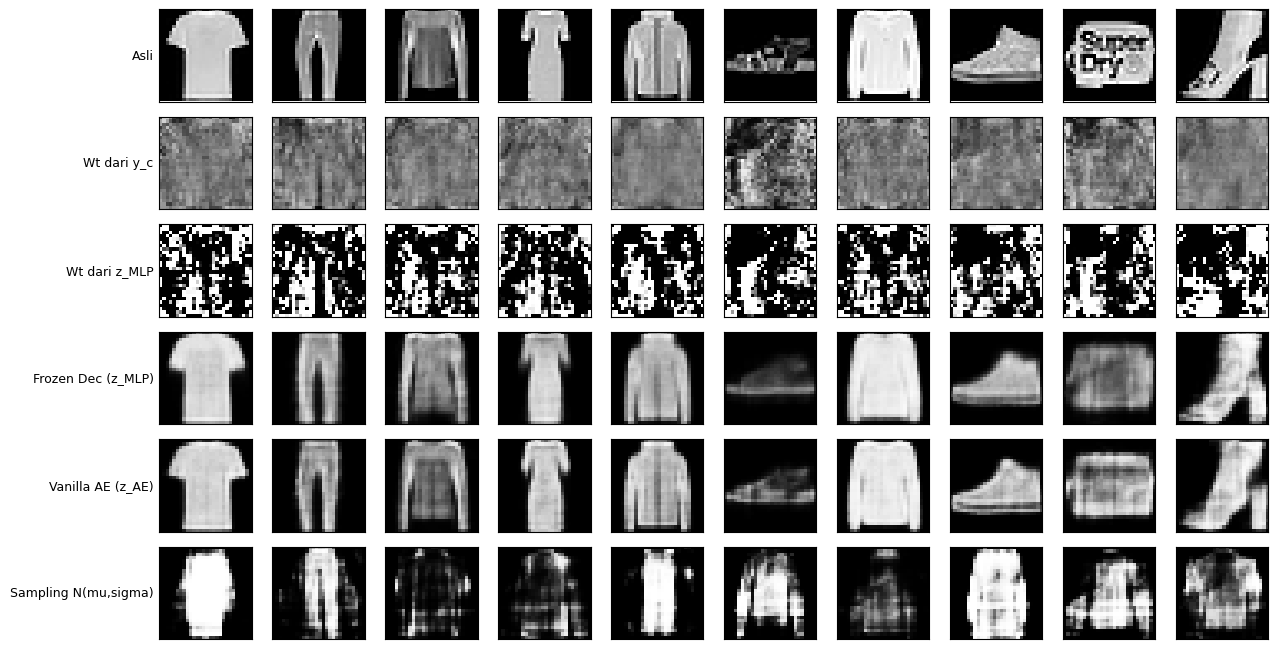

In [ ]:
with torch.no_grad():
    tampilkan_baris(
        [X_per_kelas,
         x_dari_kelas,
         x_dari_laten,
         decoder_beku(clf.fitur_laten(X_per_kelas)),
         vanilla_ae(X_per_kelas)[0],
         x_sampel_mlp],
        ["Asli", "Wt dari y_c", "Wt dari z_MLP", "Frozen Dec (z_MLP)", "Vanilla AE (z_AE)", "Sampling N(mu,sigma)"],
        "fig3_batasan_mlp.png")

# Figur 4: Interpolasi linear di ruang laten

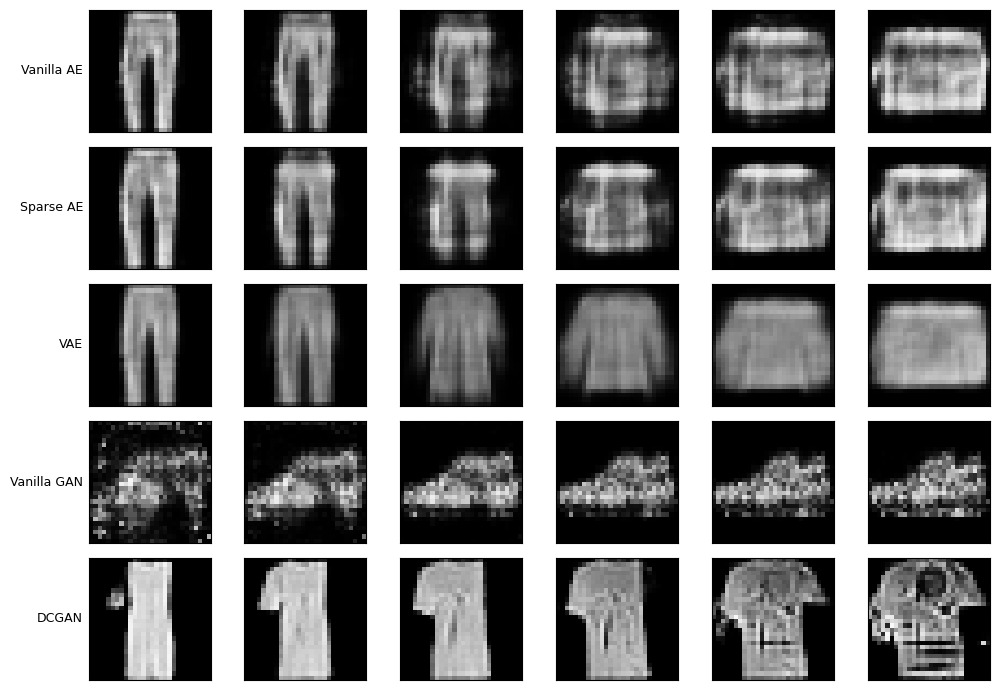

In [ ]:
daftar_alpha = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
xA = X_test[indeks_kelas[1]:indeks_kelas[1] + 1].to(device)    # Trouser
xB = X_test[indeks_kelas[8]:indeks_kelas[8] + 1].to(device)    # Bag

baris_interpolasi = []
judul_interpolasi = []

with torch.no_grad():
    # Vanilla AE dan Sparse AE
    for nama, model in [("Vanilla AE", vanilla_ae), ("Sparse AE", sparse_ae)]:
        zA = model.encode(xA)[0]
        zB = model.encode(xB)[0]
        hasil_baris = [model.decode((1 - a) * zA + a * zB) for a in daftar_alpha]
        baris_interpolasi.append(torch.cat(hasil_baris))
        judul_interpolasi.append(nama)

    # VAE (pakai mu sebagai titik laten)
    zA = vae.encode(xA)[0]
    zB = vae.encode(xB)[0]
    baris_interpolasi.append(torch.cat([vae.decode((1 - a) * zA + a * zB) for a in daftar_alpha]))
    judul_interpolasi.append("VAE")

    # Vanilla GAN dan DCGAN (pakai dua noise acak)
    kunci_seed()
    zA = torch.randn(1, NOISE_DIM, device=device)
    zB = torch.randn(1, NOISE_DIM, device=device)
    baris_interpolasi.append(torch.cat([ke_nol_satu(G_gan((1 - a) * zA + a * zB)) for a in daftar_alpha]))
    judul_interpolasi.append("Vanilla GAN")
    baris_interpolasi.append(torch.cat([ke_nol_satu(G_dc((1 - a) * zA + a * zB)) for a in daftar_alpha]))
    judul_interpolasi.append("DCGAN")

tampilkan_baris(baris_interpolasi, judul_interpolasi, "fig4_interpolasi.png", ukuran=1.4)

# Figur 5: Kurva loss dan lintasan denoising DDPM

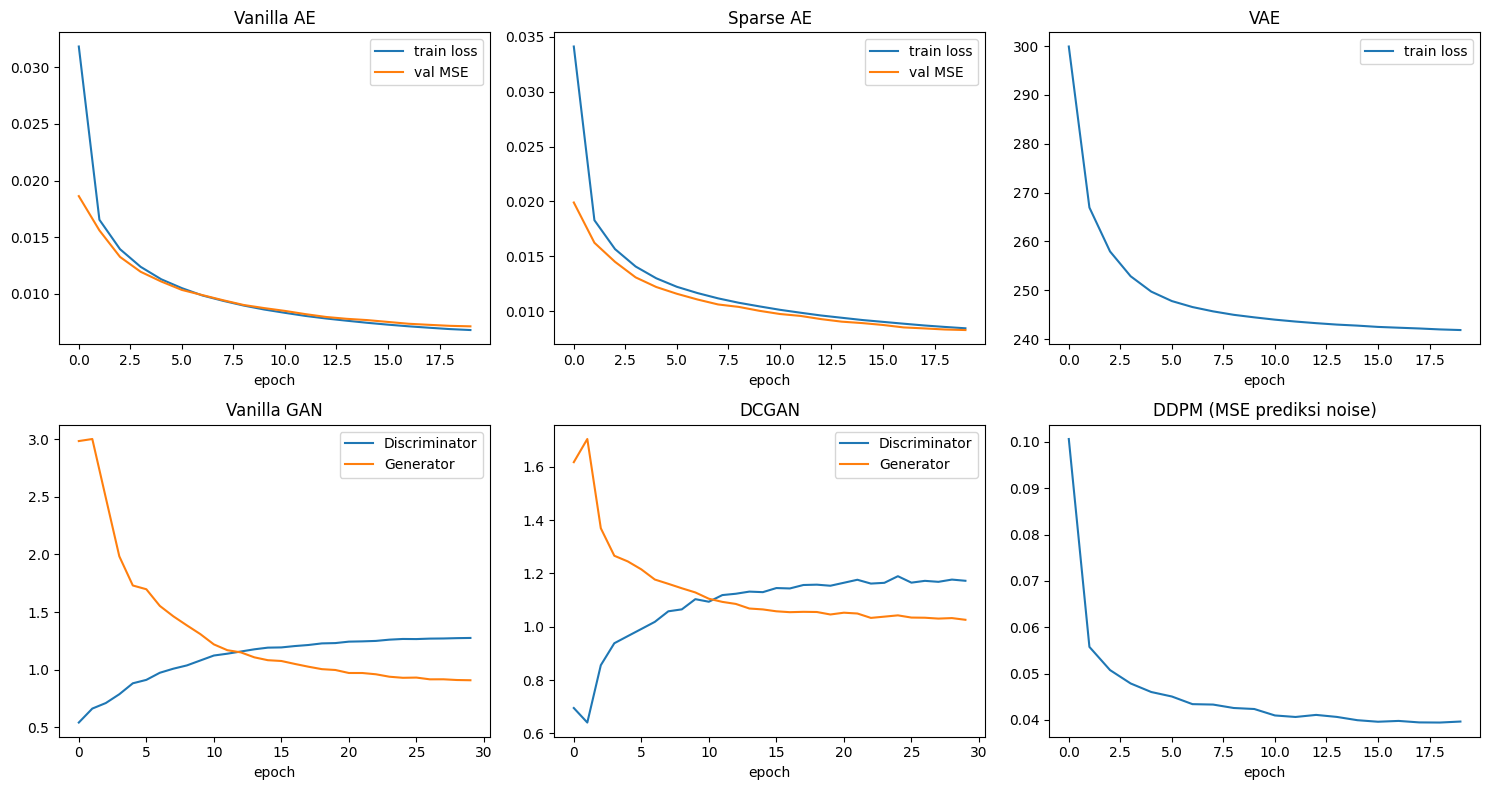

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, nama in zip(axes[:3], ["Vanilla AE", "Sparse AE", "VAE"]):
    ax.plot(riwayat[nama]["train_loss"], label="train loss")
    if "val_mse" in riwayat[nama]:
        ax.plot(riwayat[nama]["val_mse"], label="val MSE")
    ax.set_title(nama)
    ax.set_xlabel("epoch")
    ax.legend()

for ax, nama in zip(axes[3:5], ["Vanilla GAN", "DCGAN"]):
    ax.plot(riwayat[nama]["loss_d"], label="Discriminator")
    ax.plot(riwayat[nama]["loss_g"], label="Generator")
    ax.set_title(nama)
    ax.set_xlabel("epoch")
    ax.legend()

axes[5].plot(riwayat["DDPM"]["train_loss"])
axes[5].set_title("DDPM (MSE prediksi noise)")
axes[5].set_xlabel("epoch")

plt.tight_layout()
plt.savefig("figures/fig5a_kurva_loss.png", dpi=200)
plt.show()

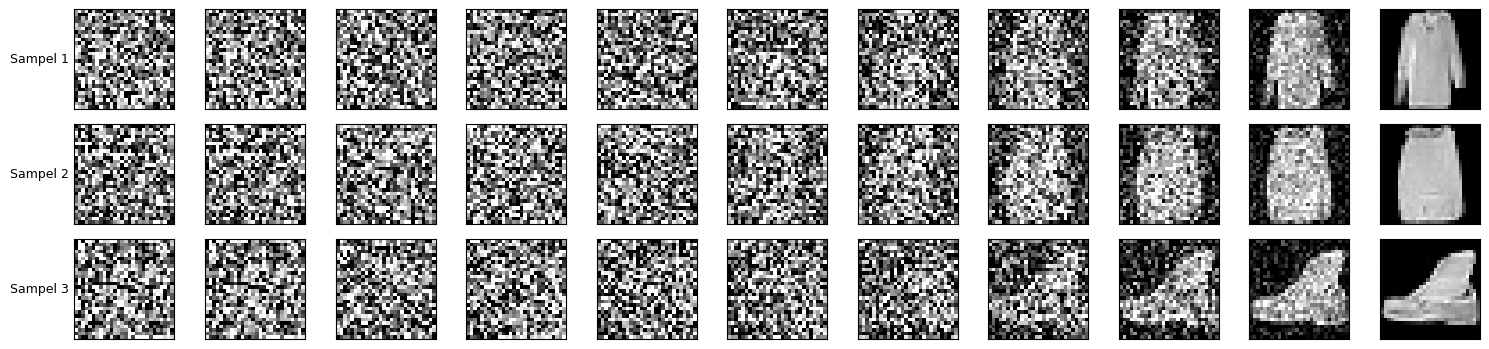

In [ ]:
kunci_seed()
_, lintasan = sampel_ddpm(3, simpan_langkah=10)
lintasan = torch.stack([ke_nol_satu(x) for x in lintasan])

tampilkan_baris(
    [lintasan[:, i] for i in range(3)],
    ["Sampel 1", "Sampel 2", "Sampel 3"],
    "fig5b_lintasan_ddpm.png", ukuran=1.2)

In [ ]:
torch.save({
    "mlp_classifier": clf.state_dict(),
    "vanilla_ae": vanilla_ae.state_dict(),
    "sparse_ae": sparse_ae.state_dict(),
    "vae": vae.state_dict(),
    "gan_generator": G_gan.state_dict(),
    "dcgan_generator": G_dc.state_dict(),
    "ddpm": ddpm.state_dict(),
}, "checkpoints/semua_model.pt")
print("Selesai! Cek folder figures/, tabel_komparasi.csv, dan tabel_mlp_vs_ae.csv")

Selesai! Cek folder figures/, tabel_komparasi.csv, dan tabel_mlp_vs_ae.csv
